# Problema 2: Regressão Logı́stica para Previsão de Doenças Cardı́acas

Nesse proejeto, eu devo construir um modelo utilizando regressão logística para prever a presença de doença cardíaca com base no conjunto de dados clínicos

# Coisas que devo fazer com o Dataset

1. Treinar um modelo de LogisticRegression do scikit-learn utilizando os dados de treino, com os seguintes parâmetros: solver=’liblinear’, random state=42 e max iter=1000. Indique quantas iterações foram necessárias para a convergência do modelo.

2. Avaliar o modelo utilizando os dados de teste e calcular as seguintes métricas: Acurácia, Precisão, Recall, F1-score e Curva ROC com valor de AUC.

**OBS** Para esse problema é preciso realizar: 

- pré-processamento dos dados, incluindo a normalização ou padronização das variáveis independentes
- tratamento de valores ausentes
- divisão dos dados em conjuntos de treino e teste
- binarização das variáveis alvo.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# importando os dados
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
heart_disease = fetch_ucirepo(id=45) 
  
# data (as pandas dataframes) 
X = heart_disease.data.features 
y = heart_disease.data.targets 

# juntando as colunas de features + target
df = pd.concat([X,y], axis=1)

# verificando a quantidade de amostras 
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(3), int64(11)
memory usage: 33.3 KB


In [4]:
# verificando a existẽncia de dados faltantes
df.isna().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64

Podemos observar que existem dados faltantes nas features `ca` e `thal`. Devemos fazer um tratamento prévio com esses dados faltantes e, para isso, **serão imputadas nesses campos as modas de `ca` e `thal`**.

O primeiro motivo para ter escolhido imputação por moda se dá primeiramente pelo fato de eu conseguir preservar as amostras e evitar que elas sejam eliminadas do dataset.

O segundo motivo está pelo fato de eu ter escolhido especificamente a imputação por moda: as variáveis são discretas (retornam valores exatos de 1,2,3...). Dessa forma, não seria interessante realizar imputação por média pois geraria valores quebrados. Já a mediana, por mais que ela seja robusta aos outliers, eu queria preencher com os valores mais comuns das features. 

In [5]:
from IPython.core.error import StdinNotImplementedError
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy='most_frequent')

X_imputed = pd.DataFrame(imputer.fit_transform(X), columns= X.columns)

# aplicando o dataframe com os valores nulos tratados no dataframe total
df = pd.concat([X_imputed,y], axis=1)
df.isna().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
num         0
dtype: int64

Agora iremos **binarizar a variável target**. Onde:

- quando o valor do campo for 0: indica sem doença, logo, valor [0] false
- quando o valor do campo for maior que 0 (1,2,3,4): indica com doença, logo, valor [1] true

In [6]:
y_binario = (y['num'] > 0).astype(int)

# aplicando o dtaframe com os valores de target tratados 
df = pd.concat([X_imputed, y_binario], axis= 1)

Vamos agora observar como está a **distribuição das classes da nossa variável target**.

In [7]:
contagem = y_binario.value_counts()
percentual = y_binario.value_counts(normalize= True) *100

print("Quantidade de amostras por classe:\n", contagem)
print("Quantidade de amostras por percentual:\n", percentual)

Quantidade de amostras por classe:
 num
0    164
1    139
Name: count, dtype: int64
Quantidade de amostras por percentual:
 num
0    54.125413
1    45.874587
Name: proportion, dtype: float64


É possível ver que as classes estão levemente desbalanceadas. Contudo, **ainda será utilizado o `stratify`** durante o split do conjunto de dados para garantir que os conjuntos de teste e de treino tenham a mesma proporção de amostras das classes 0 e 1. 

O objetivo aqui é **evitar que, devido à aleatoriedade de escolha de amostras durante o split dos dados, haja uma divisão que concentre mais pacientes doentes no treino e menos no teste** (ou vice-versa).

---

Antes da normalização, iremos primeiramente para a **divisão do conjunto de dados em treino e teste**, a proporção segue sendo 80/20.

In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X_imputed, y_binario, random_state= 42, test_size= 0.2, stratify= y_binario)

Vamos verificar agora o por que será necessário realizar a normalização dos dados por meio do boxplot das features de entrada do modelo.

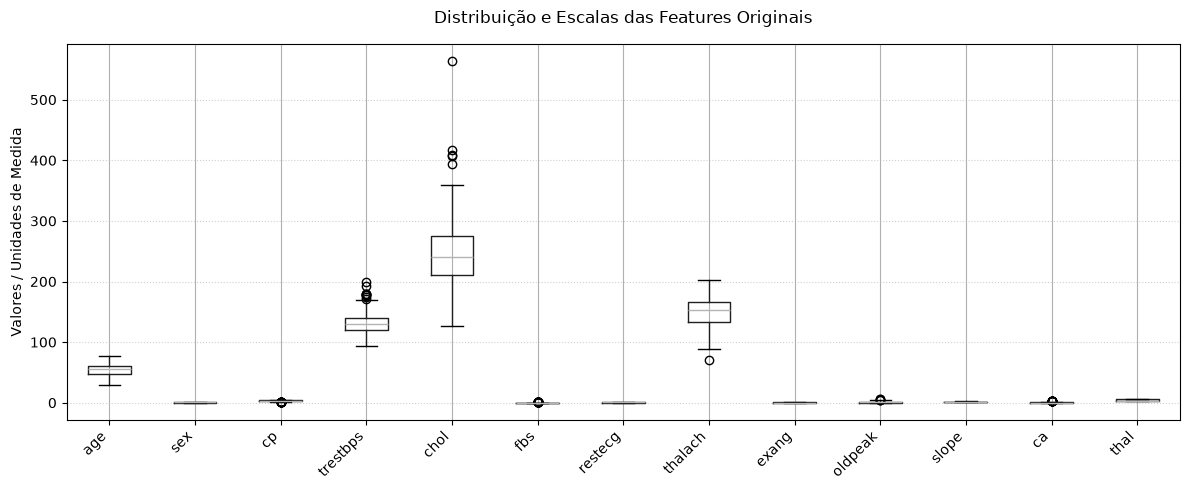

In [9]:
plt.figure(figsize=(12, 5))

X_imputed.boxplot()

plt.title('Distribuição e Escalas das Features Originais', fontsize=12, pad=15)
plt.ylabel('Valores / Unidades de Medida', fontsize=10)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.grid(axis='y', linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

Vemos então que **existe a necessidade de realizar a normalização das escalas das features de entrada do modelo** pois existem features como `chol`, `trestbps` e `thalach` que possuem uma escala com magnitude maior. Diferentemente da maioria das outras features que operam sob uma faixa de valores com magnitude baixa, por serem consideradas como variáveis binárias e/ou categóricas.

Da forma como atualmente está, a feature de colesterol (`chol`) está esmagando todas features categóricas e binárias.

In [10]:
# normalizando as escalas dos dados 
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

/tmp/ipykernel_9762/3725670561.py:12: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(loc='upper right')


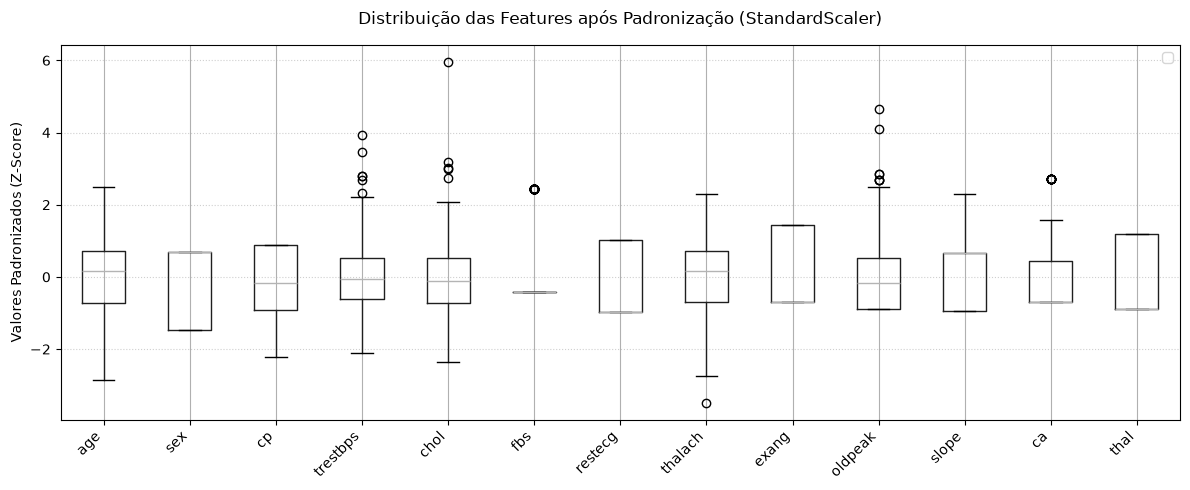

In [11]:
# array numpy -> Dataframe pandas (manter o padrão das colunas)
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns= X_train.columns)

# plotando o boxplot pós-normalização
plt.figure(figsize=(12, 5))
X_train_scaled_df.boxplot()

plt.title('Distribuição das Features após Padronização (StandardScaler)', fontsize=12, pad=15)
plt.ylabel('Valores Padronizados (Z-Score)', fontsize=10)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.legend(loc='upper right')

plt.tight_layout()
plt.show()

## 1. Treinar um modelo de LogisticRegression do scikit-learn utilizando os dados de treino, com os seguintes parâmetros: solver=’liblinear’, random state=42 e max iter=1000. Indique quantas iterações foram necessárias para a convergência do modelo.

Com as etapas anteriores já feitas, vamos criar e treinar o modelo.

In [12]:
from sklearn.linear_model import LogisticRegression

# treinando o modelo
model = LogisticRegression(solver= 'liblinear', random_state= 42, max_iter= 1000)
model.fit(X_train_scaled, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l

In [13]:
# número de iteraeções até a convergência
iteracoes = model.n_iter_[0]
print("Quantidade de iterações até a convergência: ",iteracoes)

Quantidade de iterações até a convergência:  5


## 2. Avaliar o modelo utilizando os dados de teste e calcular as seguintes métricas: Acurácia, Precisão, Recall, F1-score e Curva ROC com valor de AUC.

Para avaliar o modelo, vamos realizar a predição do modelo utilizando o conjunto de dados de teste que foi separado. 

Em seguida, serão calculadas as métricas para que, a partir delas, seja possível avaliar o modelo por elas.

In [14]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_curve, roc_auc_score

# fazendo as predições
y_pred = model.predict(X_test_scaled)

# calculando a probabilidade positiva (1 = doença) p/ a curva ROC/AUC
y_prob = model.predict_proba(X_test_scaled)[:,1]

# métricas
acuracia = accuracy_score(y_test, y_pred)
precisao = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)

print("Acurácia: ", acuracia)
print("Precisão: ", precisao)
print("Recall: ", recall)
print("F1-Score: ", f1)
print("AUC: ", auc)

Acurácia:  0.8688524590163934
Precisão:  0.8125
Recall:  0.9285714285714286
F1-Score:  0.8666666666666667
AUC:  0.9512987012987013


A partir da análise da acurácia, é possível visualizar que o modelo acerta aproximadamente 87% de todas as previsões. O F1-Score possui uma percentagem similar e indica um equilibrio entre detectar casos positivos e evitar alarmes falsos (precisão e recall). De forma geral, o desempenho geral foi ok e consistente. Contudo, isso não será o suficiente para determinarmos se o modelo proposto é bom para esse problema. 

<Figure size 500x400 with 0 Axes>

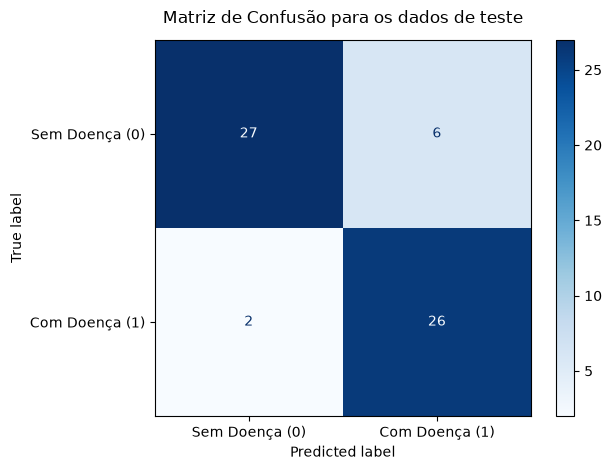

In [15]:
from sklearn.metrics import ConfusionMatrixDisplay

# verificando a matriz confusão 
plt.figure(figsize=(5, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test, 
    y_pred,
    display_labels=['Sem Doença (0)', 'Com Doença (1)'],
    cmap='Blues'
)

plt.title('Matriz de Confusão para os dados de teste', fontsize=12, pad=12)
plt.grid(False)

plt.tight_layout()
plt.show()

Nesse sentido, o modelo não favorece diretamente nenhuma das classes. Contudo, a principal métrica que devemos analisar para saber se o modelo está cumprindo o seu papel ou não é o **Recall**. É muito mais importante para o contexto do problema, detectarmos dentre todos os pacientes quais realmente tinham doença cardíaca, ou seja, precisamos verificar a taxa de falsos negativos. Podemos notar pela matriz de confusão que o modelo conseguiu identificar 26 dos 28 pacientes que estavam doentes.

Tivemos no total 8 erros: 6 deles foram de quando o modelo classificou uma pessoa não doente como doente (falso positivo). Nesse caso, pode ser considerado como um erro de menor importância em comparação aos outros 2 erros (falso negativo), já que o modelo diagnosticou com doença, um paciente que não tem ela.

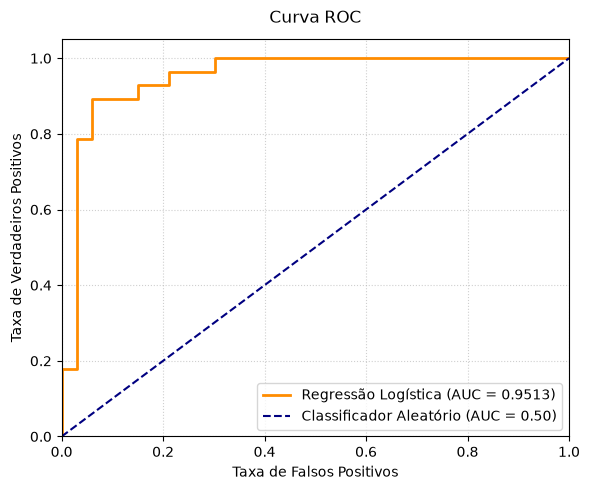

In [16]:
# calculando a taxa de falsos positivos (fpr) e verdadeiros positivos (tpr)
fpr, tpr, thresholds = roc_curve(y_test, y_prob)


plt.figure(figsize=(6, 5))

# linha do modelo
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'Regressão Logística (AUC = {auc:.4f})')

# linha de referência aleatória (linha diagonal)
plt.plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--', label='Classificador Aleatório (AUC = 0.50)')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taxa de Falsos Positivos', fontsize=10)
plt.ylabel('Taxa de Verdadeiros Positivos', fontsize=10)
plt.title('Curva ROC', fontsize=12, pad=12)
plt.legend(loc="lower right", fontsize=10)
plt.grid(linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

Ao visualizar a curva ROC, podemos perceber que a curva no final, pega 95,13% da área do gráfico. Isso demonstra que o modelo de regressão logística foi capaz de atingir taxas elevadas de verdadeiros positivos mantendo taxa reduzidas de falsos positivos (falsos alarmes). Isso significa que o modelo consegue prever de forma correta e com mais frequência os pacientes que realmente possuem a doença cardíaca do que prever que um paciente possui uma doença sem ele realmente ter.

Vale mencionar que a curva ROC é excessivamente otimista para dados desbalanceados severamente, que não é o caso. Mas por isso, tem-se a necessidade de avaliar não só a curva ROC ou a métrica ROC-AUC.

---

Ao final, é possível concluir que sim, esse é um modelo que teve bons resultados mas que poderia ser melhorado para que futuramente, mitigasse para zero a quantidade de falsos negativos. Foi justamente por isso que o recall foi uma das métricas principais a serem analisadas.